In [9]:
import os
import re
import glob
from pathlib import Path

import pandas as pd

# =========================================================
# CONFIG
# =========================================================
SEG_DIR = "/ix1/alee/LO_LAB/General/Lab_Data/20250924_IMPACT_MSKCC_pILC_Rahul/segment_files"
GENE_BED = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/GRCh37_refseq_ncbi/refseq_grch37_all_gene.bed"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV"

os.makedirs(OUTDIR, exist_ok=True)

# =========================================================
# HELPERS
# =========================================================
def clean_chr(x):
    x = str(x).strip()
    x = re.sub(r"^chr", "", x, flags=re.IGNORECASE)
    return x

def unique_join(values, sep=";"):
    vals = pd.Series(values).dropna().astype(str).unique().tolist()
    vals = sorted([v for v in vals if v != ""])
    if len(vals) == 0:
        return pd.NA
    return sep.join(vals)

# =========================================================
# LOAD GENE BED
# BED format:
# chr1   117   14749   CTSE   GeneID:1510   -
#
# BED start is 0-based, end is 1-based.
# Convert start to 1-based so it matches loc.start / loc.end logic.
# =========================================================
genes = pd.read_csv(
    GENE_BED,
    sep="\t",
    header=None,
    usecols=[0, 1, 2, 3, 4, 5],
    names=["chrom", "bed_start", "bed_end", "Gene", "Gene_ID", "Strand"]
)

genes["chrom"] = genes["chrom"].astype(str).map(clean_chr)
genes["bed_start"] = pd.to_numeric(genes["bed_start"], errors="coerce")
genes["bed_end"] = pd.to_numeric(genes["bed_end"], errors="coerce")

genes = genes.dropna(subset=["bed_start", "bed_end", "Gene"]).copy()

# Convert BED start (0-based) to 1-based inclusive start
genes["gene_start"] = genes["bed_start"].astype(int) + 1
genes["gene_end"] = genes["bed_end"].astype(int)

# keep only useful columns
genes = genes[["chrom", "gene_start", "gene_end", "Gene", "Gene_ID", "Strand"]].copy()

print("[INFO] Loaded genes:", genes.shape[0])
display(genes.head())

# Split once by chromosome for speed
genes_by_chr = {chrom: df.reset_index(drop=True) for chrom, df in genes.groupby("chrom")}

# =========================================================
# ANNOTATE ONE SEGMENT FILE
# Adds:
#   Gene_Names  -> semicolon-separated overlapping genes
#   Gene_IDs    -> semicolon-separated overlapping GeneIDs
#   Gene_Count  -> number of unique overlapping genes
# =========================================================
def annotate_segment_file(seg_file):
    df = pd.read_csv(seg_file, sep="\t")
    sample_name = Path(seg_file).stem

    required_cols = ["ID", "chrom", "loc.start", "loc.end"]
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{sample_name}: missing required columns -> {missing}")

    df["chrom_clean"] = df["chrom"].astype(str).map(clean_chr)
    df["loc.start"] = pd.to_numeric(df["loc.start"], errors="coerce")
    df["loc.end"] = pd.to_numeric(df["loc.end"], errors="coerce")

    gene_names_out = []
    gene_count_out = []

    for _, row in df.iterrows():
        chrom = row["chrom_clean"]
        seg_start = row["loc.start"]
        seg_end = row["loc.end"]

        if pd.isna(seg_start) or pd.isna(seg_end):
            gene_names_out.append(pd.NA)
            gene_count_out.append(0)
            continue

        genes_chr = genes_by_chr.get(chrom, None)
        if genes_chr is None or genes_chr.empty:
            gene_names_out.append(pd.NA)
            gene_count_out.append(0)
            continue

        # overlap condition
        hits = genes_chr[
            (genes_chr["gene_start"] <= seg_end) &
            (genes_chr["gene_end"] >= seg_start)
        ]

        gene_names = unique_join(hits["Gene"])
        gene_count = hits["Gene"].dropna().astype(str).nunique()

        gene_names_out.append(gene_names)
        gene_count_out.append(gene_count)

    df["Gene_Names"] = gene_names_out
    df["Gene_Count"] = gene_count_out

    df = df.drop(columns=["chrom_clean"])

    out_file = os.path.join(OUTDIR, f"{sample_name}.segments_with_genes.tsv")
    df.to_csv(out_file, sep="\t", index=False)

    return sample_name, out_file, df.shape[0]

# =========================================================
# RUN FOR ALL FILES
# =========================================================
seg_files = sorted(glob.glob(os.path.join(SEG_DIR, "*.txt")))
print(f"[INFO] Found {len(seg_files)} segment files")

if len(seg_files) == 0:
    raise FileNotFoundError(f"No .txt files found in: {SEG_DIR}")

summary_rows = []

for seg_file in seg_files:
    sample_name, out_file, n_rows = annotate_segment_file(seg_file)
    summary_rows.append([sample_name, out_file, n_rows])
    print(f"[INFO] Saved: {out_file}")

summary_df = pd.DataFrame(summary_rows, columns=["Sample", "Output_File", "N_Segments"])
summary_file = os.path.join(OUTDIR, "segments_with_genes_file_summary.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)

print(f"[INFO] Summary saved: {summary_file}")
display(summary_df.head())

[INFO] Loaded genes: 50316


,chrom,gene_start,gene_end,Gene,Gene_ID,Strand
0,1,118,14749,CTSE,GeneID:1510,-
1,1,549,141236,NOTCH2,GeneID:4853,-
2,1,5292,16348,NBPF12,GeneID:149013,-
3,1,6671,8428,LINC01134,GeneID:100133612,+
4,1,7274,18867,MTX1,GeneID:4580,+


[INFO] Found 32 segment files
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP03-117T_TP03-117NL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP04-104T_TP04-104NL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP05-1063T_TP05-1063NL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP05-232T_TP05-232NL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP05-668T_TP05-668NL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP05-726T_TP05-726NL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP05-791T_FFPEPOOLEDNORMAL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP07-172T_FFPEPOOLEDNORMAL.segments_with_genes.tsv
[INFO] Saved: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/TP

,Sample,Output_File,N_Segments
0,TP03-117T_TP03-117NL,/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPAC...,41
1,TP04-104T_TP04-104NL,/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPAC...,25
2,TP05-1063T_TP05-1063NL,/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPAC...,36
3,TP05-232T_TP05-232NL,/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPAC...,23
4,TP05-668T_TP05-668NL,/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPAC...,33


In [10]:
import os
import glob
import pandas as pd

# =========================================================
# CONFIG
# =========================================================
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV"

files = sorted(glob.glob(os.path.join(OUTDIR, "*.segments_with_genes.tsv")))
print(f"[INFO] Found {len(files)} annotated segment files")

summary_list = []

for fp in files:
    df = pd.read_csv(fp, sep="\t")

    # numeric safety
    df["loc.start"] = pd.to_numeric(df["loc.start"], errors="coerce")
    df["loc.end"]   = pd.to_numeric(df["loc.end"], errors="coerce")

    # segment size
    df["Segment_Size_bp"] = df["loc.end"] - df["loc.start"] + 1
    df["Segment_Size_Mb"] = df["Segment_Size_bp"] / 1e6

    # optional: round Mb for readability
    df["Segment_Size_Mb"] = df["Segment_Size_Mb"].round(3)

    # save back
    df.to_csv(fp, sep="\t", index=False)

    sample_id = df["ID"].iloc[0] if "ID" in df.columns and len(df) > 0 else os.path.basename(fp)

    summary_list.append({
        "ID": sample_id,
        "N_segments": len(df),
        "Min_Segment_Mb": df["Segment_Size_Mb"].min(),
        "Median_Segment_Mb": df["Segment_Size_Mb"].median(),
        "Mean_Segment_Mb": df["Segment_Size_Mb"].mean(),
        "Max_Segment_Mb": df["Segment_Size_Mb"].max(),
        "Segments_gt_10Mb": (df["Segment_Size_Mb"] > 10).sum(),
        "Segments_gt_50Mb": (df["Segment_Size_Mb"] > 50).sum()
    })

summary_df = pd.DataFrame(summary_list)
summary_df = summary_df.sort_values("ID").reset_index(drop=True)

summary_file = os.path.join(OUTDIR, "segment_size_summary_across_samples.tsv")
summary_df.to_csv(summary_file, sep="\t", index=False)

print(f"[INFO] Saved summary: {summary_file}")
display(summary_df)

[INFO] Found 32 annotated segment files
[INFO] Saved summary: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/segment_size_summary_across_samples.tsv


,ID,N_segments,Min_Segment_Mb,Median_Segment_Mb,Mean_Segment_Mb,Max_Segment_Mb,Segments_gt_10Mb,Segments_gt_50Mb
0,TP03-117T_TP03-117NL,41,0.413,55.3730,69.961293,242.524,36,21
1,TP04-104T_TP04-104NL,25,10.312,132.9630,116.624600,246.788,25,20
2,TP05-1063T_TP05-1063NL,36,3.576,65.5435,80.408417,242.524,32,24
3,TP05-232T_TP05-232NL,23,34.051,133.0530,126.833261,246.788,23,21
4,TP05-668T_TP05-668NL,33,0.920,61.9810,87.575424,246.788,29,20
5,TP05-726T_TP05-726NL,25,32.606,93.9820,116.561720,246.788,25,22
6,TP05-791T_FFPEPOOLEDNORMAL,41,0.030,50.9350,70.723537,242.524,38,21
7,TP07-172T_FFPEPOOLEDNORMAL,25,15.394,132.9630,116.685120,242.524,25,21
8,TP07-197T_FFPEPOOLEDNORMAL,30,0.888,83.4585,96.625033,242.524,27,21
9,TP07-626T_FFPEPOOLEDNORMAL,32,1.686,78.4955,90.564219,242.524,31,23


In [16]:
# Create the arm table from UCSC file
import pandas as pd
import re

# =========================================================
# PATHS
# =========================================================
CYTOBAND_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/UCSC_hg19/cytoBandIdeo.txt"

# =========================================================
# HELPERS
# =========================================================
def clean_chr(x):
    x = str(x).strip()
    x = re.sub(r"^chr", "", x, flags=re.IGNORECASE)
    return x

# =========================================================
# LOAD CYTOBAND
# UCSC coordinates:
#   chromStart = 0-based
#   chromEnd   = end position
# =========================================================
cyto = pd.read_csv(
    CYTOBAND_FILE,
    sep="\t",
    header=None,
    names=["chrom", "chromStart", "chromEnd", "band", "gieStain"]
)

cyto["chrom"] = cyto["chrom"].astype(str).map(clean_chr)

# keep autosomes + X only
chrom_order = [str(i) for i in range(1, 23)] + ["X"]
cyto = cyto[cyto["chrom"].isin(chrom_order)].copy()

# arm letter comes from band name: p36.33 -> p, q21.1 -> q
cyto["arm_letter"] = cyto["band"].astype(str).str[0]
cyto = cyto[cyto["arm_letter"].isin(["p", "q"])].copy()

# =========================================================
# DERIVE ARM START/END
# convert UCSC 0-based start to 1-based inclusive start
# so it matches your segment loc.start / loc.end coordinates
# =========================================================
arms = (
    cyto.groupby(["chrom", "arm_letter"], as_index=False)
    .agg(
        arm_start0=("chromStart", "min"),
        arm_end=("chromEnd", "max")
    )
)

arms["arm_start"] = arms["arm_start0"] + 1
arms["Arm"] = arms["chrom"] + arms["arm_letter"]

arms = arms[["chrom", "Arm", "arm_start", "arm_end"]].copy()

# order as 1p,1q,2p,2q,...
arm_order = []
for c in chrom_order:
    for arm in [f"{c}p", f"{c}q"]:
        if arm in arms["Arm"].values:
            arm_order.append(arm)

arms["Arm"] = pd.Categorical(arms["Arm"], categories=arm_order, ordered=True)
arms = arms.sort_values(["chrom", "Arm"]).reset_index(drop=True)

display(arms)
print("[INFO] Number of arms:", arms.shape[0])

,chrom,Arm,arm_start,arm_end
0,1,1p,1,125000000
1,1,1q,125000001,249250621
2,10,10p,1,40200000
3,10,10q,40200001,135534747
4,11,11p,1,53700000
5,11,11q,53700001,135006516
6,12,12p,1,35800000
7,12,12q,35800001,133851895
8,13,13p,1,17900000
9,13,13q,17900001,115169878


[INFO] Number of arms: 46


[INFO] Found 32 segment files
[INFO] Combined rows: 1018
[INFO] Unique samples: 32
[INFO] Chromosomes plotted: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22']
[INFO] Chromosome sizes loaded from: /ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/UCSC_hg19/cytoBandIdeo.txt
[INFO] Plotting 32 samples in 8 rows x 4 cols


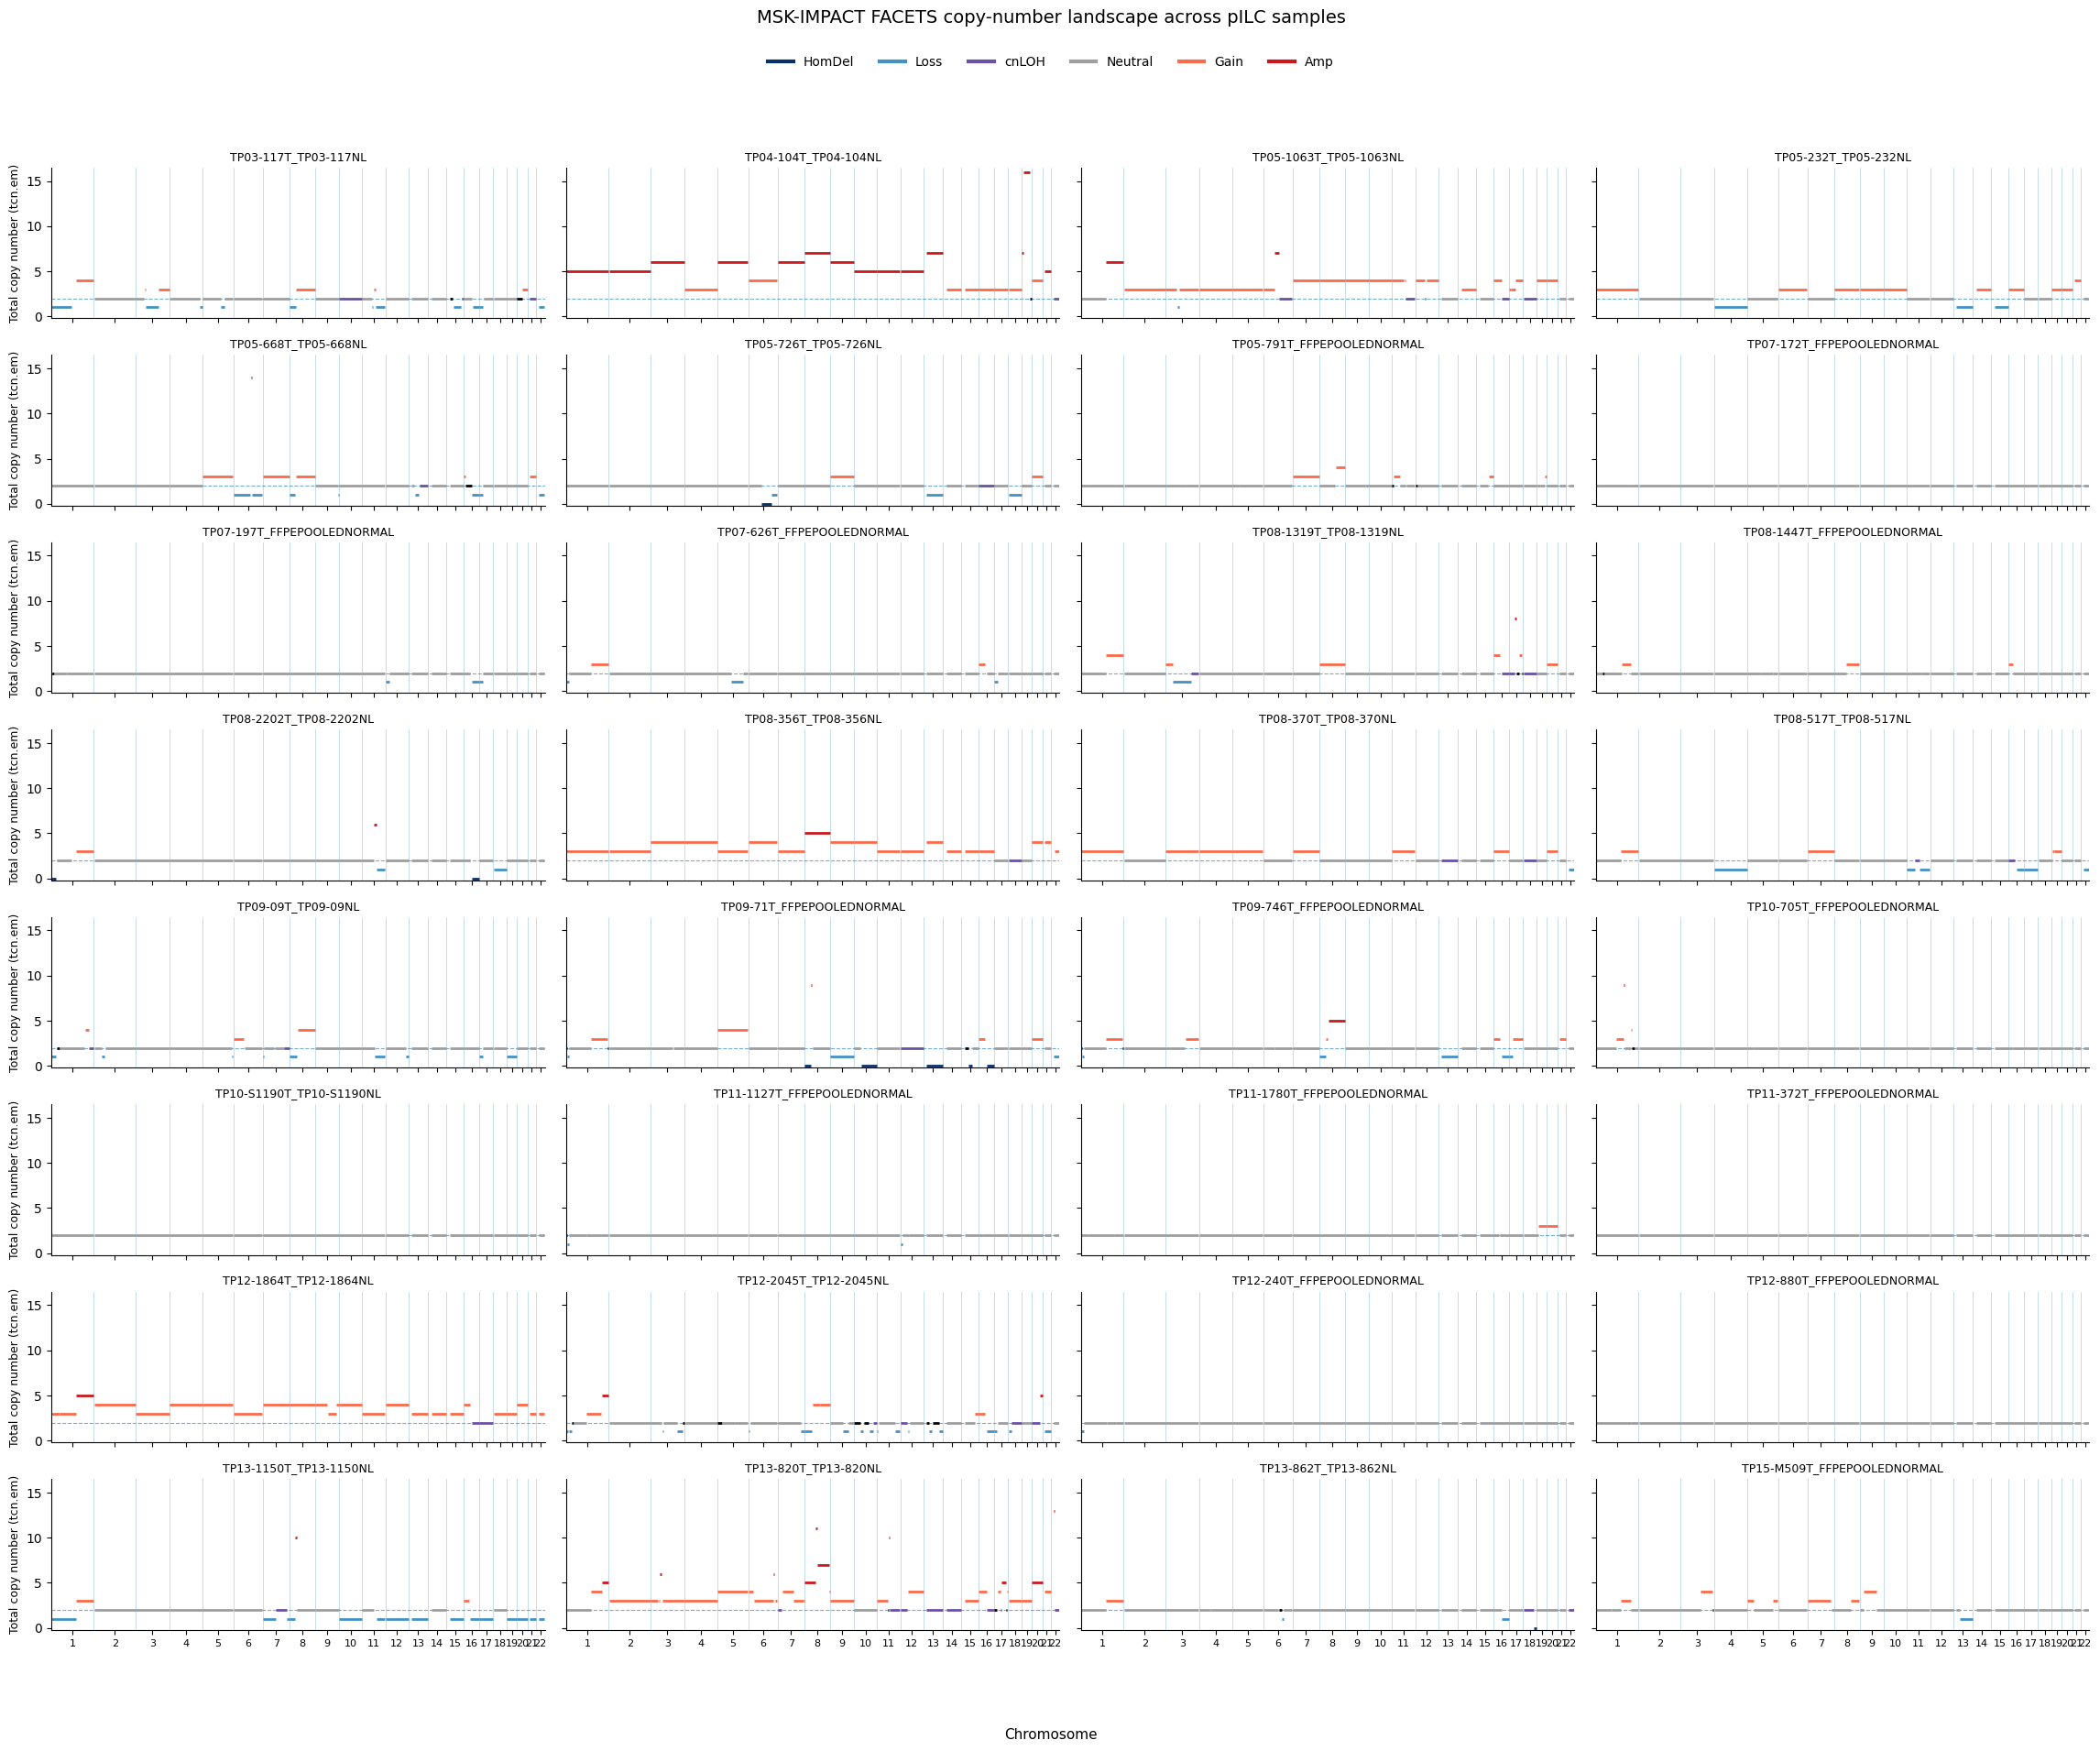

[INFO] Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/Plot/MSK_IMPACT_faceted_genomewide_CNV_tcn.png
[INFO] Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/Plot/MSK_IMPACT_faceted_genomewide_CNV_tcn.pdf


In [2]:
import os
import re
import glob
import math
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# =========================================================
# CONFIG
# =========================================================
SEG_DIR = "/ix1/alee/LO_LAB/General/Lab_Data/20250924_IMPACT_MSKCC_pILC_Rahul/segment_files"
CYTOBAND_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/UCSC_hg19/cytoBandIdeo.txt"
OUTDIR  = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/Plot"
os.makedirs(OUTDIR, exist_ok=True)

OUT_PNG = os.path.join(OUTDIR, "MSK_IMPACT_faceted_genomewide_CNV_tcn.png")
OUT_PDF = os.path.join(OUTDIR, "MSK_IMPACT_faceted_genomewide_CNV_tcn.pdf")

# layout
N_COLS = 4
PANEL_W = 6
PANEL_H = 2.4

# choose what to plot on y-axis
# "tcn" = absolute total copy number (recommended here)
# "cnlr" = segmented log-ratio
Y_MODE = "tcn"

# =========================================================
# HELPERS
# =========================================================
def clean_chr(x):
    x = str(x).strip()
    x = re.sub(r"^chr", "", x, flags=re.IGNORECASE)
    return x

def classify_cna(tcn, lcn):
    if pd.isna(tcn):
        return "NA"
    try:
        tcn = int(round(float(tcn)))
    except Exception:
        return "NA"

    try:
        lcn = int(round(float(lcn))) if not pd.isna(lcn) else None
    except Exception:
        lcn = None

    if tcn == 0:
        return "HomDel"
    elif tcn == 1:
        return "Loss"
    elif tcn == 2 and lcn == 0:
        return "cnLOH"
    elif tcn == 2 and lcn == 1:
        return "Neutral"
    elif tcn in [3, 4]:
        return "Gain"
    elif tcn >= 5:
        return "Amp"
    else:
        return "Other"

# =========================================================
# LOAD ALL SEGMENT FILES
# =========================================================
seg_files = sorted(glob.glob(os.path.join(SEG_DIR, "*.txt")))
print(f"[INFO] Found {len(seg_files)} segment files")

if len(seg_files) == 0:
    raise FileNotFoundError(f"No .txt files found in: {SEG_DIR}")

required_cols = [
    "ID", "chrom", "loc.start", "loc.end",
    "cnlr.median", "tcn.em", "lcn.em"
]

all_dfs = []

for fp in seg_files:
    df = pd.read_csv(fp, sep="\t")
    sample_name = Path(fp).stem

    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{sample_name}: missing required columns -> {missing}")

    df = df[required_cols].copy()
    df["chrom"] = df["chrom"].astype(str).map(clean_chr)

    for col in ["loc.start", "loc.end", "cnlr.median", "tcn.em", "lcn.em"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["CN_State"] = df.apply(lambda x: classify_cna(x["tcn.em"], x["lcn.em"]), axis=1)
    all_dfs.append(df)

seg = pd.concat(all_dfs, ignore_index=True)

print("[INFO] Combined rows:", seg.shape[0])
print("[INFO] Unique samples:", seg["ID"].nunique())

# =========================================================
# CHROMOSOME ORDER AND SIZES FROM UCSC cytoBandIdeo.txt
# =========================================================
cyto = pd.read_csv(
    CYTOBAND_FILE,
    sep="\t",
    header=None,
    names=["chrom", "chromStart", "chromEnd", "band", "gieStain"]
)

cyto["chrom"] = cyto["chrom"].astype(str).map(clean_chr)
cyto["chromStart"] = pd.to_numeric(cyto["chromStart"], errors="coerce")
cyto["chromEnd"] = pd.to_numeric(cyto["chromEnd"], errors="coerce")

# keep standard chromosomes only
chrom_order_full = [str(i) for i in range(1, 23)] + ["X", "Y"]
cyto = cyto[cyto["chrom"].isin(chrom_order_full)].copy()

# chromosome size = max chromEnd from cytoband file
chr_sizes = (
    cyto.groupby("chrom", as_index=False)["chromEnd"]
    .max()
    .rename(columns={"chromEnd": "chr_size"})
)

chr_sizes["chrom"] = pd.Categorical(
    chr_sizes["chrom"],
    categories=chrom_order_full,
    ordered=True
)
chr_sizes = chr_sizes.sort_values("chrom").reset_index(drop=True)

chr_size_dict = dict(zip(chr_sizes["chrom"].astype(str), chr_sizes["chr_size"]))

# only chromosomes actually present in your segment table
chroms_present = [c for c in chrom_order_full if c in seg["chrom"].astype(str).unique()]

# cumulative offsets
offsets = {}
centers = {}
running = 0

for chrom in chroms_present:
    chrom_size = chr_size_dict[chrom]
    offsets[chrom] = running
    centers[chrom] = running + (chrom_size / 2.0)
    running += chrom_size

genome_size = running
print("[INFO] Chromosomes plotted:", chroms_present)
print("[INFO] Chromosome sizes loaded from:", CYTOBAND_FILE)

# =========================================================
# MAP SEGMENTS TO GENOME-WIDE X COORDINATES
# =========================================================
seg = seg[seg["chrom"].isin(chroms_present)].copy()
seg["xstart"] = seg.apply(lambda x: offsets[x["chrom"]] + x["loc.start"], axis=1)
seg["xend"]   = seg.apply(lambda x: offsets[x["chrom"]] + x["loc.end"], axis=1)

if Y_MODE == "tcn":
    seg["yval"] = seg["tcn.em"]
    y_label = "Total copy number (tcn.em)"
    ref_line = 2
    y_min = max(-0.2, seg["yval"].min(skipna=True) - 0.3)
    y_max = seg["yval"].max(skipna=True) + 0.5
else:
    seg["yval"] = seg["cnlr.median"]
    y_label = "Segment log-ratio (cnlr.median)"
    ref_line = 0
    y_min = seg["yval"].min(skipna=True) - 0.2
    y_max = seg["yval"].max(skipna=True) + 0.2

# =========================================================
# COLORS
# =========================================================
state_colors = {
    "HomDel": "#08306B",
    "Loss":   "#4292C6",
    "cnLOH":  "#6A51A3",
    "Neutral":"#9E9E9E",
    "Gain":   "#FB6A4A",
    "Amp":    "#CB181D",
    "Other":  "#000000",
    "NA":     "#BDBDBD"
}

# =========================================================
# SAMPLE ORDER
# =========================================================
sample_order = sorted(seg["ID"].dropna().unique().tolist())
n_samples = len(sample_order)
n_rows = math.ceil(n_samples / N_COLS)

print("[INFO] Plotting", n_samples, "samples in", n_rows, "rows x", N_COLS, "cols")

# =========================================================
# PLOT
# =========================================================
fig, axes = plt.subplots(
    n_rows, N_COLS,
    figsize=(N_COLS * PANEL_W, n_rows * PANEL_H),
    sharex=True,
    sharey=True
)

# make axes always iterable
if n_rows == 1 and N_COLS == 1:
    axes = [[axes]]
elif n_rows == 1:
    axes = [axes]
elif N_COLS == 1:
    axes = [[ax] for ax in axes]

axes_flat = [ax for row in axes for ax in row]

for i, sample_id in enumerate(sample_order):
    ax = axes_flat[i]
    d = seg[seg["ID"] == sample_id].copy()
    d = d.sort_values(["chrom", "loc.start", "loc.end"])

    # chromosome boundaries
    for chrom in chroms_present:
        ax.axvline(offsets[chrom], linewidth=0.5, alpha=0.35)

    # reference line
    ax.axhline(ref_line, linewidth=0.8, linestyle="--", alpha=0.6)

    # draw each segment
    for _, row in d.iterrows():
        ax.hlines(
            y=row["yval"],
            xmin=row["xstart"],
            xmax=row["xend"],
            color=state_colors.get(row["CN_State"], "#000000"),
            linewidth=2.0
        )

    ax.set_title(sample_id, fontsize=9)
    ax.set_xlim(0, genome_size)
    ax.set_ylim(y_min, y_max)

    # cleaner style
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# turn off unused panels
for j in range(n_samples, len(axes_flat)):
    axes_flat[j].axis("off")

# x ticks at chromosome centers
xticks = [centers[c] for c in chroms_present]
xticklabels = chroms_present

for idx, ax in enumerate(axes_flat[:n_samples]):
    row_i = idx // N_COLS
    col_i = idx % N_COLS

    if row_i == n_rows - 1:
        ax.set_xticks(xticks)
        ax.set_xticklabels(xticklabels, fontsize=8)
    else:
        ax.set_xticks(xticks)
        ax.set_xticklabels([])

    if col_i == 0:
        ax.set_ylabel(y_label, fontsize=9)

# figure-level labels
fig.supxlabel("Chromosome", fontsize=11)
fig.suptitle("MSK-IMPACT FACETS copy-number landscape across pILC samples", fontsize=14, y=0.995)

# legend
legend_order = ["HomDel", "Loss", "cnLOH", "Neutral", "Gain", "Amp"]
legend_handles = [
    Line2D([0], [0], color=state_colors[s], lw=3, label=s)
    for s in legend_order
]

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.975),
    ncol=len(legend_handles),
    frameon=False,
    fontsize=10
)

plt.tight_layout(rect=[0.02, 0.04, 0.98, 0.94])

plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print(f"[INFO] Saved PNG: {OUT_PNG}")
print(f"[INFO] Saved PDF: {OUT_PDF}")

[INFO] Saved arm reference: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/hg19_chr_arms_from_cytoband.tsv


,chrom,Arm,arm_start,arm_end
0,1,1p,1,125000000
1,1,1q,125000001,249250621
2,10,10p,1,40200000
3,10,10q,40200001,135534747
4,11,11p,1,53700000
5,11,11q,53700001,135006516
6,12,12p,1,35800000
7,12,12q,35800001,133851895
8,13,13p,1,17900000
9,13,13q,17900001,115169878


[INFO] Found 32 segment files
[INFO] Combined rows: 972
[INFO] Unique samples: 32
[INFO] Saved arm summary: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/chromosome_arm_dominant_state_by_sample.tsv


,ID,Arm,CN_State,Overlap_bp,Priority,Arm_Size_bp,Dominant_Fraction
0,TP03-117T_TP03-117NL,10p,cnLOH,39740093,2,40200000,0.988560
1,TP03-117T_TP03-117NL,10q,cnLOH,93999067,2,95334747,0.985990
2,TP03-117T_TP03-117NL,11p,Neutral,53167260,1,53700000,0.990079
3,TP03-117T_TP03-117NL,11q,Loss,61767436,3,81306516,0.759686
4,TP03-117T_TP03-117NL,12p,Neutral,35405204,1,35800000,0.988972
5,TP03-117T_TP03-117NL,12q,Neutral,97647331,1,98051895,0.995874
6,TP03-117T_TP03-117NL,13q,Neutral,93981893,1,97269878,0.966197
7,TP03-117T_TP03-117NL,14q,Neutral,85558510,1,89749540,0.953303
8,TP03-117T_TP03-117NL,15q,Loss,44924265,3,83531392,0.537813
9,TP03-117T_TP03-117NL,16p,Neutral,36484958,1,36600000,0.996857


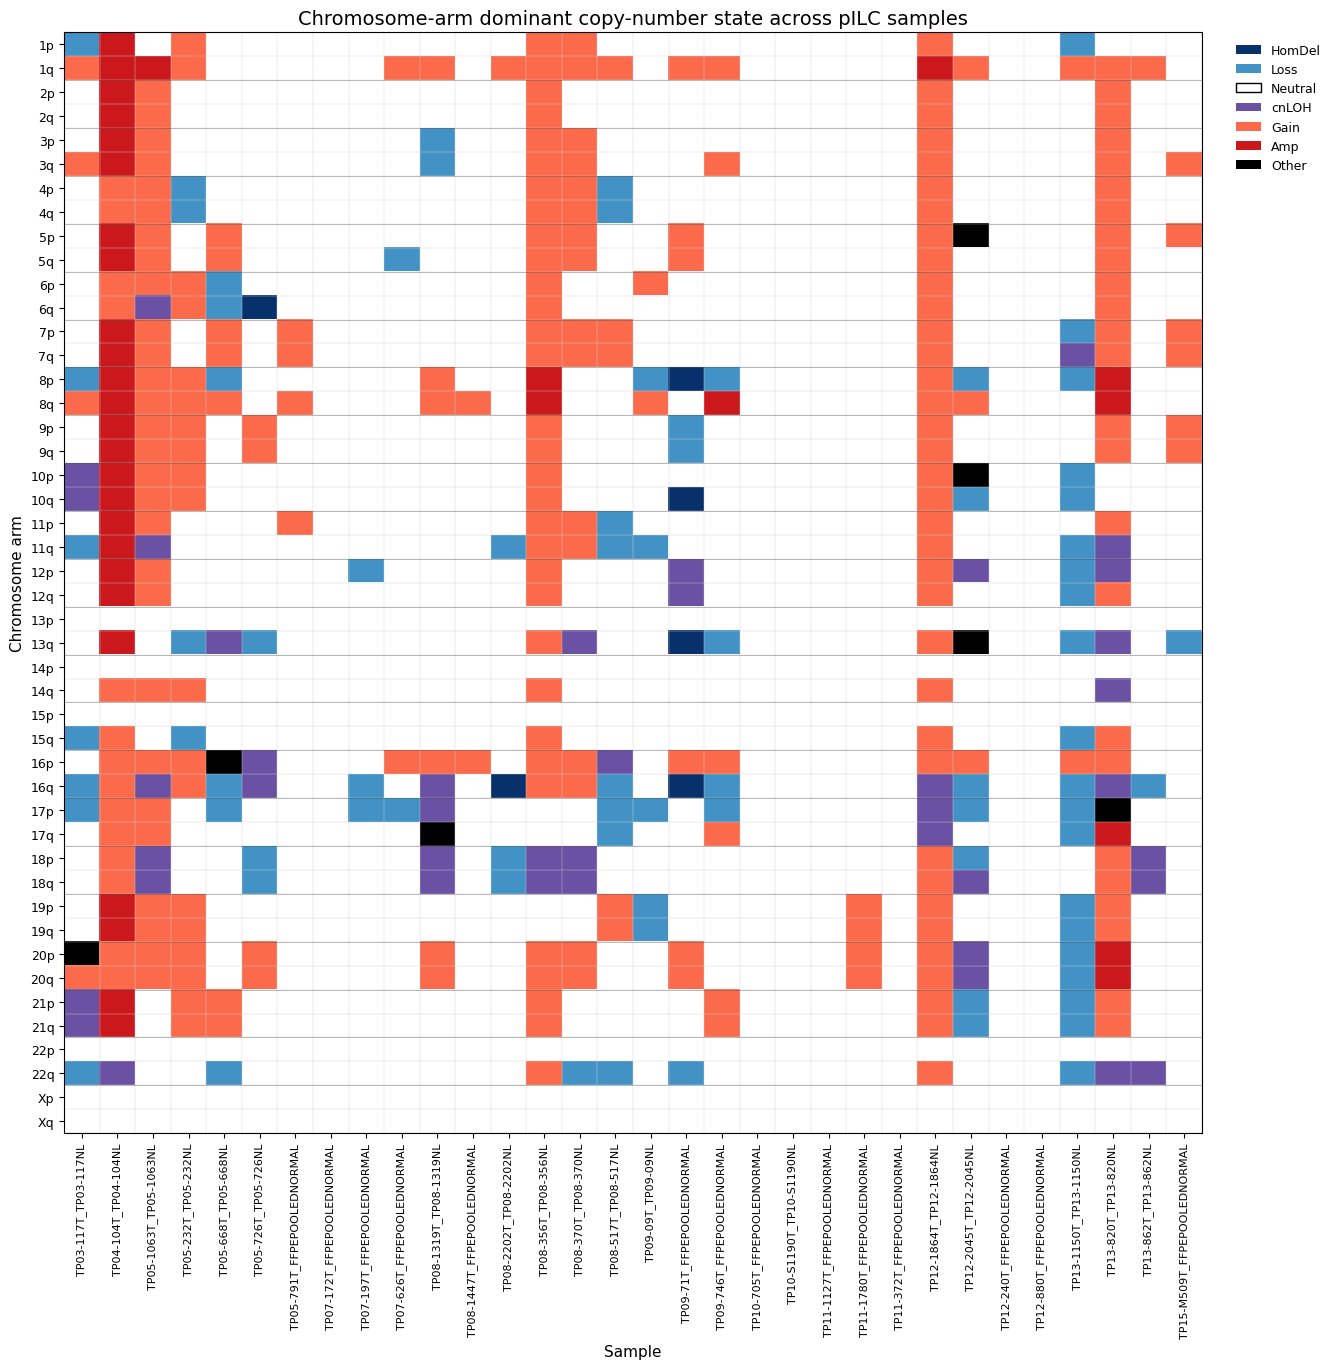

[INFO] Saved PNG: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/MSK_IMPACT_chromosome_arm_heatmap.png
[INFO] Saved PDF: /ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV/MSK_IMPACT_chromosome_arm_heatmap.pdf


In [17]:
import os
import re
import glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

# =========================================================
# CONFIG
# =========================================================
SEG_DIR = "/ix1/alee/LO_LAB/General/Lab_Data/20250924_IMPACT_MSKCC_pILC_Rahul/segment_files"
CYTOBAND_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/Reference_genome/Human/UCSC_hg19/cytoBandIdeo.txt"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/pILC/MSK_IMPACT/CNV"
os.makedirs(OUTDIR, exist_ok=True)

ARM_REF_OUT = os.path.join(OUTDIR, "hg19_chr_arms_from_cytoband.tsv")
ARM_SUMMARY_OUT = os.path.join(OUTDIR, "chromosome_arm_dominant_state_by_sample.tsv")
OUT_PNG = os.path.join(OUTDIR, "MSK_IMPACT_chromosome_arm_heatmap.png")
OUT_PDF = os.path.join(OUTDIR, "MSK_IMPACT_chromosome_arm_heatmap.pdf")

# =========================================================
# HELPERS
# =========================================================
def clean_chr(x):
    x = str(x).strip()
    x = re.sub(r"^chr", "", x, flags=re.IGNORECASE)
    return x

def classify_cna(tcn, lcn):
    if pd.isna(tcn):
        return "NA"
    try:
        tcn = int(round(float(tcn)))
    except Exception:
        return "NA"

    try:
        lcn = int(round(float(lcn))) if not pd.isna(lcn) else None
    except Exception:
        lcn = None

    if tcn == 0:
        return "HomDel"
    elif tcn == 1:
        return "Loss"
    elif tcn == 2 and lcn == 0:
        return "cnLOH"
    elif tcn == 2 and lcn == 1:
        return "Neutral"
    elif tcn in [3, 4]:
        return "Gain"
    elif tcn >= 5:
        return "Amp"
    else:
        return "Other"

# =========================================================
# 1. LOAD CYTOBAND AND DERIVE CHROMOSOME ARMS
# UCSC cytoBandIdeo:
# chrom, chromStart, chromEnd, band, gieStain
# chromStart is 0-based; convert arm_start to 1-based
# =========================================================
cyto = pd.read_csv(
    CYTOBAND_FILE,
    sep="\t",
    header=None,
    names=["chrom", "chromStart", "chromEnd", "band", "gieStain"]
)

cyto["chrom"] = cyto["chrom"].astype(str).map(clean_chr)

# keep autosomes + X only
chrom_order = [str(i) for i in range(1, 23)] + ["X"]
cyto = cyto[cyto["chrom"].isin(chrom_order)].copy()

# p/q arm from band name
cyto["arm_letter"] = cyto["band"].astype(str).str[0]
cyto = cyto[cyto["arm_letter"].isin(["p", "q"])].copy()

# derive arm coordinates
arms = (
    cyto.groupby(["chrom", "arm_letter"], as_index=False)
    .agg(
        arm_start0=("chromStart", "min"),
        arm_end=("chromEnd", "max")
    )
)

# convert to 1-based inclusive to match loc.start / loc.end
arms["arm_start"] = arms["arm_start0"] + 1
arms["Arm"] = arms["chrom"] + arms["arm_letter"]

arms = arms[["chrom", "Arm", "arm_start", "arm_end"]].copy()

# order as 1p,1q,2p,2q,...,Xp,Xq
arm_order = []
for c in chrom_order:
    for a in [f"{c}p", f"{c}q"]:
        if a in arms["Arm"].values:
            arm_order.append(a)

arms["Arm"] = pd.Categorical(arms["Arm"], categories=arm_order, ordered=True)
arms = arms.sort_values(["chrom", "Arm"]).reset_index(drop=True)

arms.to_csv(ARM_REF_OUT, sep="\t", index=False)
print(f"[INFO] Saved arm reference: {ARM_REF_OUT}")
display(arms.head(10))

# =========================================================
# 2. LOAD FACETS SEGMENTS
# =========================================================
seg_files = sorted(glob.glob(os.path.join(SEG_DIR, "*.txt")))
print(f"[INFO] Found {len(seg_files)} segment files")

if len(seg_files) == 0:
    raise FileNotFoundError(f"No .txt files found in: {SEG_DIR}")

required_cols = ["ID", "chrom", "loc.start", "loc.end", "tcn.em", "lcn.em"]

all_dfs = []
for fp in seg_files:
    df = pd.read_csv(fp, sep="\t")
    sample_name = Path(fp).stem

    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{sample_name}: missing required columns -> {missing}")

    df = df[required_cols].copy()
    df["chrom"] = df["chrom"].astype(str).map(clean_chr)

    for col in ["loc.start", "loc.end", "tcn.em", "lcn.em"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["CN_State"] = df.apply(lambda x: classify_cna(x["tcn.em"], x["lcn.em"]), axis=1)
    all_dfs.append(df)

seg = pd.concat(all_dfs, ignore_index=True)
seg = seg[seg["chrom"].isin(chrom_order)].copy()

print("[INFO] Combined rows:", seg.shape[0])
print("[INFO] Unique samples:", seg["ID"].nunique())

# =========================================================
# 3. OVERLAP SEGMENTS WITH CHROMOSOME ARMS
# overlap condition on 1-based inclusive coordinates
# =========================================================
overlap_rows = []

for _, s in seg.iterrows():
    sample_id = s["ID"]
    chrom = s["chrom"]
    seg_start = s["loc.start"]
    seg_end = s["loc.end"]
    state = s["CN_State"]

    if pd.isna(seg_start) or pd.isna(seg_end):
        continue

    arm_sub = arms[arms["chrom"] == chrom]

    for _, a in arm_sub.iterrows():
        ov_start = max(seg_start, a["arm_start"])
        ov_end = min(seg_end, a["arm_end"])

        if ov_start <= ov_end:
            overlap_bp = ov_end - ov_start + 1
            overlap_rows.append([sample_id, chrom, a["Arm"], state, overlap_bp])

ov = pd.DataFrame(overlap_rows, columns=["ID", "chrom", "Arm", "CN_State", "Overlap_bp"])

# =========================================================
# 4. SUMMARIZE BP COVERAGE PER SAMPLE x ARM x STATE
# choose dominant state per arm by largest bp coverage
# =========================================================
state_bp = (
    ov.groupby(["ID", "Arm", "CN_State"], as_index=False)["Overlap_bp"]
    .sum()
)

state_priority = {
    "Amp": 6,
    "HomDel": 5,
    "Gain": 4,
    "Loss": 3,
    "cnLOH": 2,
    "Neutral": 1,
    "Other": 0,
    "NA": -1
}

state_bp["Priority"] = state_bp["CN_State"].map(state_priority).fillna(-1)

dominant = (
    state_bp.sort_values(
        ["ID", "Arm", "Overlap_bp", "Priority"],
        ascending=[True, True, False, False]
    )
    .drop_duplicates(subset=["ID", "Arm"], keep="first")
    .copy()
)

# add arm size and dominant fraction
arm_sizes = arms.copy()
arm_sizes["Arm_Size_bp"] = arm_sizes["arm_end"] - arm_sizes["arm_start"] + 1
arm_sizes = arm_sizes[["Arm", "Arm_Size_bp"]]

dominant = dominant.merge(arm_sizes, on="Arm", how="left")
dominant["Dominant_Fraction"] = dominant["Overlap_bp"] / dominant["Arm_Size_bp"]

dominant = dominant.sort_values(["ID", "Arm"]).reset_index(drop=True)
dominant.to_csv(ARM_SUMMARY_OUT, sep="\t", index=False)

print(f"[INFO] Saved arm summary: {ARM_SUMMARY_OUT}")
display(dominant.head(10))

# =========================================================
# 5. BUILD HEATMAP MATRIX
# =========================================================
sample_order = sorted(dominant["ID"].unique().tolist())

state_to_num = {
    "HomDel": -2,
    "Loss": -1,
    "Neutral": 0,
    "cnLOH": 0.5,
    "Gain": 1,
    "Amp": 2,
    "Other": 3,
    "NA": np.nan
}

heat = dominant.pivot(index="Arm", columns="ID", values="CN_State")
heat = heat.reindex(index=arm_order, columns=sample_order)
heat_num = heat.replace(state_to_num)

# =========================================================
# 6. PLOT HEATMAP
# Neutral is white
# =========================================================
cmap = ListedColormap([
    "#08306B",  # HomDel
    "#4292C6",  # Loss
    "white",    # Neutral
    "#6A51A3",  # cnLOH
    "#FB6A4A",  # Gain
    "#CB181D",  # Amp
    "#000000"   # Other
])

# values: -2, -1, 0, 0.5, 1, 2, 3
bounds = [-2.5, -1.5, -0.5, 0.25, 0.75, 1.5, 2.5, 3.5]
norm = BoundaryNorm(bounds, cmap.N)

fig_w = max(12, 0.42 * len(sample_order))
fig_h = max(10, 0.30 * len(arm_order))

fig, ax = plt.subplots(figsize=(fig_w, fig_h))
im = ax.imshow(heat_num.values, aspect="auto", interpolation="none", cmap=cmap, norm=norm)

ax.set_xticks(np.arange(len(sample_order)))
ax.set_xticklabels(sample_order, rotation=90, fontsize=8)

ax.set_yticks(np.arange(len(arm_order)))
ax.set_yticklabels(arm_order, fontsize=9)

ax.set_xlabel("Sample", fontsize=11)
ax.set_ylabel("Chromosome arm", fontsize=11)
ax.set_title("Chromosome-arm dominant copy-number state across pILC samples", fontsize=14)

# light grid so white neutral cells remain visible
ax.set_xticks(np.arange(-0.5, len(sample_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(arm_order), 1), minor=True)
ax.grid(which="minor", color="lightgray", linestyle="-", linewidth=0.3)
ax.tick_params(which="minor", bottom=False, left=False)

# subtle separators after each chromosome (after q arm)
for i in range(2, len(arm_order), 2):
    ax.axhline(i - 0.5, color="black", linewidth=0.5, alpha=0.35)

legend_handles = [
    Patch(facecolor="#08306B", edgecolor="none", label="HomDel"),
    Patch(facecolor="#4292C6", edgecolor="none", label="Loss"),
    Patch(facecolor="white", edgecolor="black", label="Neutral"),
    Patch(facecolor="#6A51A3", edgecolor="none", label="cnLOH"),
    Patch(facecolor="#FB6A4A", edgecolor="none", label="Gain"),
    Patch(facecolor="#CB181D", edgecolor="none", label="Amp"),
    Patch(facecolor="#000000", edgecolor="none", label="Other"),
]

ax.legend(
    handles=legend_handles,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=9
)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()

print(f"[INFO] Saved PNG: {OUT_PNG}")
print(f"[INFO] Saved PDF: {OUT_PDF}")